# Import required libraries and config

In [ ]:
import re
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---- Config ----
CSV_PATH = "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"
NUM_WORDS = 20000
MAXLEN = 300
EMBED_DIM = 300
GLOVE_PICKLE_PATH = "/kaggle/input/datasets/authman/pickled-glove840b300d-for-10sec-loading/glove.840B.300d.pkl"
BATCH_SIZE = 128
EPOCHS = 20
RANDOM_STATE = 42

# Load the data

In [ ]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
print(df["sentiment"].value_counts())

(50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


data cleanning

In [ ]:
def clean_text(text: str) -> str:
    text = re.sub(r"<.*?>", " ", text)          # strip HTML tags like <br />
    text = re.sub(r"[^a-zA-Z']", " ", text)      # keep letters and apostrophes only
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text


df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})

# Split into train,val,test

In [ ]:
# ---- 2. Split 70 / 15 / 15 ----
# First split off 70% train, 30% temp
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["label"]
)
# Split the 30% temp into two equal 15% halves -> val and test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["label"]
)

print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Val:   {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test:  {len(test_df)} ({len(test_df)/len(df):.1%})")


Train: 35000 (70.0%)
Val:   7500 (15.0%)
Test:  7500 (15.0%)


# Tokenization

In [ ]:
# ---- 3. Tokenize (fit ONLY on train to avoid leakage) ----
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean_review"])

def to_padded_sequences(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")

x_train = to_padded_sequences(train_df["clean_review"])
x_val = to_padded_sequences(val_df["clean_review"])
x_test = to_padded_sequences(test_df["clean_review"])

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

# Save tokenizer for inference later
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

# pre-trained gloVe load

In [ ]:
# ---- 4. Load GloVe and build embedding matrix ----
print("Loading GloVe vectors from pickle...")
with open(GLOVE_PICKLE_PATH, "rb") as f:
    glove_vectors = pickle.load(f)
print(f"Loaded {len(glove_vectors)} word vectors")

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
hits, misses = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    vec = glove_vectors.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        hits += 1
    else:
        misses += 1
print(f"GloVe coverage: {hits} hits, {misses} misses")

Loading GloVe vectors from pickle...
Loaded 2196008 word vectors
GloVe coverage: 19085 hits, 914 misses


# Buid model

In [ ]:
model = Sequential([
    Embedding(
        input_dim=vocab_size, output_dim=EMBED_DIM,
        weights=[embedding_matrix], input_length=MAXLEN,
        trainable=True,
    ),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(128, return_sequences=True, recurrent_dropout=0.2)),
    Bidirectional(LSTM(64, recurrent_dropout=0.2)),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1788065517.472891      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 6,000,000 (22.89 MB)

 Non-trainable params: 0 (0.00 B)

# training

In [ ]:
# ---- Train with callbacks ----
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint(
        "imdb_bilstm_best.h5",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,          # prints a message each time it saves a new best model
    ),
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,               # shows loss, accuracy, val_loss, val_accuracy every epoch
)



Epoch 1/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6607 - loss: 0.6008
Epoch 1: val_accuracy improved from None to 0.84613, saving model to imdb_bilstm_best.h5



Epoch 1: finished saving model to imdb_bilstm_best.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 647s 2s/step - accuracy: 0.7395 - loss: 0.5242 - val_accuracy: 0.8461 - val_loss: 0.3654 - learning_rate: 0.0010
Epoch 2/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8393 - loss: 0.3804
Epoch 2: val_accuracy improved from 0.84613 to 0.88133, saving model to imdb_bilstm_best.h5



Epoch 2: finished saving model to imdb_bilstm_best.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 636s 2s/step - accuracy: 0.8548 - loss: 0.3556 - val_accuracy: 0.8813 - val_loss: 0.2837 - learning_rate: 0.0010
Epoch 3/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9007 - loss: 0.2633
Epoch 3: val_accuracy did not improve from 0.88133
274/274 ━━━━━━━━━━━━━━━━━━━━ 625s 2s/step - accuracy: 0.8979 - loss: 0.2677 - val_accuracy: 0.8184 - val_loss: 0.3986 - learning_rate: 0.0010
Epoch 4/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9033 - loss: 0.2558
Epoch 4: val_accuracy improved from 0.88133 to 0.89533, saving model to imdb_bilstm_best.h5



Epoch 4: finished saving model to imdb_bilstm_best.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 636s 2s/step - accuracy: 0.9151 - loss: 0.2291 - val_accuracy: 0.8953 - val_loss: 0.2604 - learning_rate: 0.0010
Epoch 5/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9350 - loss: 0.1845
Epoch 5: val_accuracy did not improve from 0.89533
274/274 ━━━━━━━━━━━━━━━━━━━━ 624s 2s/step - accuracy: 0.9352 - loss: 0.1824 - val_accuracy: 0.8919 - val_loss: 0.2839 - learning_rate: 0.0010
Epoch 6/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9506 - loss: 0.1461
Epoch 6: val_accuracy did not improve from 0.89533
274/274 ━━━━━━━━━━━━━━━━━━━━ 641s 2s/step - accuracy: 0.9496 - loss: 0.1493 - val_accuracy: 0.8928 - val_loss: 0.2897 - learning_rate: 0.0010
Epoch 7/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9615 - loss: 0.1153
Epoch 7: val_accuracy did not improve from 0.89533
274/274 ━━━━━━━━━━━━━━━━━━━━ 625s 2s/step - accuracy: 0.9637 - loss: 0.1108 - val_accuracy: 0.8935 - val_loss: 

In [ ]:
# ---- Final explicit save (in case you want the LAST epoch too, not just best) ----
model.save("imdb_bilstm_final.h5")
print("Saved final model to imdb_bilstm_final.h5")

# ---- Save tokenizer — required for the Gradio app to preprocess raw text later ----
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved tokenizer to tokenizer.pkl")

Saved final model to imdb_bilstm_final.h5
Saved tokenizer to tokenizer.pkl


change

In [ ]:
!pip install contractions -q

In [ ]:
"""
Re-run in your ACTIVE Kaggle session (df, tokenizer setup, glove_vectors etc.
are assumed to already exist in memory from your previous run).

Changes vs your 89.5% run:
  1. Negation words kept in stopword removal (fixes "not good" -> "good" bug)
  2. OOV words get small random vectors instead of zeros
  3. Final BiLSTM uses GlobalMaxPooling1D instead of last-hidden-state only

Saves under NEW filenames so your original 89.5% run is preserved:
  - imdb_bilstm_best_v2.h5
  - imdb_bilstm_final_v2.h5
  - tokenizer_v2.pkl
"""

import re
import string
import pickle
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import contractions
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense, Dropout,
    SpatialDropout1D, GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

# ---- Config ----
CSV_PATH = "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"
NUM_WORDS = 20000
MAXLEN = 300
EMBED_DIM = 300
GLOVE_PICKLE_PATH = "/kaggle/input/datasets/authman/pickled-glove840b300d-for-10sec-loading/glove.840B.300d.pkl"
BATCH_SIZE = 128
EPOCHS = 20
RANDOM_STATE = 42

# ============================================================
# STEP 1 — Load data + preprocess (with negation fix)
# ============================================================
df = pd.read_csv(CSV_PATH)

initial_count = len(df)
df.drop_duplicates(subset=["review"], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Duplicates removed: {initial_count - len(df)} rows dropped, {len(df):,} remaining")

# Keep negation words -- removing them turns "was not good" into "good"
NEGATION_WORDS = {"not", "no", "nor", "never", "none", "neither", "n't"}
STOP_WORDS = set(stopwords.words("english")) - NEGATION_WORDS


def preprocess_text(text: str) -> str:
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = text.replace("\u2013", "-").replace("\u2014", "-")
    text = text.encode("ascii", errors="ignore").decode("ascii")
    text = contractions.fix(text)
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\b\d+\b", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in STOP_WORDS]
    return " ".join(tokens)


print("Preprocessing reviews (negation-safe)...")
df["clean_review"] = df["review"].apply(preprocess_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})
print("Preprocessing complete.")

# ============================================================
# STEP 2 — Split 70 / 15 / 15
# ============================================================
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["label"]
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ============================================================
# STEP 3 — Tokenize (fit on train only)
# ============================================================
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean_review"])


def to_padded_sequences(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")


x_train = to_padded_sequences(train_df["clean_review"])
x_val = to_padded_sequences(val_df["clean_review"])
x_test = to_padded_sequences(test_df["clean_review"])

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

with open("tokenizer_v2.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved tokenizer_v2.pkl")

# ============================================================
# STEP 4 — Embedding matrix (random-init OOV instead of zeros)
# ============================================================
print("Loading GloVe vectors from pickle...")
with open(GLOVE_PICKLE_PATH, "rb") as f:
    glove_vectors = pickle.load(f)
print(f"Loaded {len(glove_vectors)} word vectors")

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)

embedding_matrix = np.random.normal(0, 0.05, (vocab_size, EMBED_DIM))
embedding_matrix[0] = np.zeros(EMBED_DIM)  # padding index stays zero

hits, misses = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    vec = glove_vectors.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        hits += 1
    else:
        misses += 1  # keeps the random vector
print(f"GloVe coverage: {hits} hits, {misses} misses")

# ============================================================
# STEP 5 — Build model (GlobalMaxPooling1D instead of last state)
# ============================================================
model = Sequential([
    Embedding(
        input_dim=vocab_size, output_dim=EMBED_DIM,
        weights=[embedding_matrix], input_length=MAXLEN,
        trainable=True,
    ),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(128, return_sequences=True, recurrent_dropout=0.2)),
    Bidirectional(LSTM(64, return_sequences=True, recurrent_dropout=0.2)),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# ============================================================
# STEP 6 — Train (with per-epoch train/val acc & loss logged)
# ============================================================
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint("imdb_bilstm_best_v2.h5", monitor="val_accuracy", save_best_only=True, verbose=1),
    CSVLogger("training_log_v2.csv"),  # saves epoch-by-epoch acc/loss/val_acc/val_loss to a CSV
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

# ============================================================
# STEP 7 — Save final model + evaluate on held-out test set
# ============================================================
model.save("imdb_bilstm_final_v2.h5")
print("Saved imdb_bilstm_final_v2.h5")

loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal TEST accuracy: {acc:.4f}")

Duplicates removed: 418 rows dropped, 49,582 remaining
Preprocessing reviews (negation-safe)...
Preprocessing complete.
Train: 34707 | Val: 7437 | Test: 7438
Saved tokenizer_v2.pkl
Loading GloVe vectors from pickle...
Loaded 2196008 word vectors
GloVe coverage: 19503 hits, 496 misses


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1788074205.138206      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 6,000,000 (22.89 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7710 - loss: 0.4582
Epoch 1: val_accuracy improved from None to 0.89189, saving model to imdb_bilstm_best_v2.h5



Epoch 1: finished saving model to imdb_bilstm_best_v2.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 653s 2s/step - accuracy: 0.8369 - loss: 0.3660 - val_accuracy: 0.8919 - val_loss: 0.2659 - learning_rate: 0.0010
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9048 - loss: 0.2454
Epoch 2: val_accuracy improved from 0.89189 to 0.90265, saving model to imdb_bilstm_best_v2.h5



Epoch 2: finished saving model to imdb_bilstm_best_v2.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 653s 2s/step - accuracy: 0.9064 - loss: 0.2405 - val_accuracy: 0.9026 - val_loss: 0.2403 - learning_rate: 0.0010
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9329 - loss: 0.1799
Epoch 3: val_accuracy did not improve from 0.90265
272/272 ━━━━━━━━━━━━━━━━━━━━ 646s 2s/step - accuracy: 0.9323 - loss: 0.1833 - val_accuracy: 0.8884 - val_loss: 0.2681 - learning_rate: 0.0010
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9523 - loss: 0.1356
Epoch 4: val_accuracy did not improve from 0.90265
272/272 ━━━━━━━━━━━━━━━━━━━━ 642s 2s/step - accuracy: 0.9521 - loss: 0.1368 - val_accuracy: 0.9014 - val_loss: 0.2738 - learning_rate: 0.0010
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9711 - loss: 0.0858
Epoch 5: val_accuracy did not improve from 0.90265
272/272 ━━━━━━━━━━━━━━━━━━━━ 646s 2s/step - accuracy: 0.9707 - loss: 0.0847 - val_accuracy: 0.9010 - val_los

Saved imdb_bilstm_final_v2.h5

Final TEST accuracy: 0.9020


Still, there is significant overfitting. So let's try some other ways to improve

# Freezing the embedding

Fix: freeze the embeddings, or fine-tune them more gently.

In [ ]:
!pip install contractions -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 9.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.6 MB/s eta 0:00:00


In [ ]:
import re
import string
import pickle
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import contractions
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense, Dropout,
    SpatialDropout1D, GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

# ---- Config ----
CSV_PATH = "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"
NUM_WORDS = 20000
MAXLEN = 300
EMBED_DIM = 300
GLOVE_PICKLE_PATH = "/kaggle/input/datasets/authman/pickled-glove840b300d-for-10sec-loading/glove.840B.300d.pkl"
BATCH_SIZE = 128
EPOCHS = 20
RANDOM_STATE = 42

# ============================================================
# STEP 1 — Load data + preprocess (with negation fix)
# ============================================================
df = pd.read_csv(CSV_PATH)

initial_count = len(df)
df.drop_duplicates(subset=["review"], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Duplicates removed: {initial_count - len(df)} rows dropped, {len(df):,} remaining")

# Keep negation words -- removing them turns "was not good" into "good"
NEGATION_WORDS = {"not", "no", "nor", "never", "none", "neither", "n't"}
STOP_WORDS = set(stopwords.words("english")) - NEGATION_WORDS


def preprocess_text(text: str) -> str:
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = text.replace("\u2013", "-").replace("\u2014", "-")
    text = text.encode("ascii", errors="ignore").decode("ascii")
    text = contractions.fix(text)
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\b\d+\b", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in STOP_WORDS]
    return " ".join(tokens)


print("Preprocessing reviews (negation-safe)...")
df["clean_review"] = df["review"].apply(preprocess_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})
print("Preprocessing complete.")

# ============================================================
# STEP 2 — Split 70 / 15 / 15
# ============================================================
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["label"]
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ============================================================
# STEP 3 — Tokenize (fit on train only)
# ============================================================
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean_review"])


def to_padded_sequences(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")


x_train = to_padded_sequences(train_df["clean_review"])
x_val = to_padded_sequences(val_df["clean_review"])
x_test = to_padded_sequences(test_df["clean_review"])

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

with open("tokenizer_freez.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved tokenizer_freez.pkl")

# ============================================================
# STEP 4 — Embedding matrix (random-init OOV instead of zeros)
# ============================================================
print("Loading GloVe vectors from pickle...")
with open(GLOVE_PICKLE_PATH, "rb") as f:
    glove_vectors = pickle.load(f)
print(f"Loaded {len(glove_vectors)} word vectors")

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)

embedding_matrix = np.random.normal(0, 0.05, (vocab_size, EMBED_DIM))
embedding_matrix[0] = np.zeros(EMBED_DIM)  # padding index stays zero

hits, misses = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    vec = glove_vectors.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        hits += 1
    else:
        misses += 1  # keeps the random vector
print(f"GloVe coverage: {hits} hits, {misses} misses")

# ============================================================
# STEP 5 — Build model (GlobalMaxPooling1D instead of last state)
# ============================================================
model = Sequential([
    Embedding(
        input_dim=vocab_size, output_dim=EMBED_DIM,
        weights=[embedding_matrix], input_length=MAXLEN,
        trainable=False,   # was True — freezing removes 6M trainable params
    ),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(128, return_sequences=True, recurrent_dropout=0.2)),
    Bidirectional(LSTM(64, return_sequences=True, recurrent_dropout=0.2)),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# ============================================================
# STEP 6 — Train (with per-epoch train/val acc & loss logged)
# ============================================================
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint("imdb_bilstm_best_freez.h5", monitor="val_accuracy", save_best_only=True, verbose=1),
    CSVLogger("training_log_freez.csv"),  # saves epoch-by-epoch acc/loss/val_acc/val_loss to a CSV
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

# ============================================================
# STEP 7 — Save final model + evaluate on held-out test set
# ============================================================
model.save("imdb_bilstm_final_freez.h5")
print("Saved imdb_bilstm_final_freez.h5")

loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal TEST accuracy: {acc:.4f}")

Duplicates removed: 418 rows dropped, 49,582 remaining
Preprocessing reviews (negation-safe)...
Preprocessing complete.
Train: 34707 | Val: 7437 | Test: 7438
Saved tokenizer_freez.pkl
Loading GloVe vectors from pickle...
Loaded 2196008 word vectors
GloVe coverage: 19503 hits, 496 misses


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1788837192.841231      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 0 (0.00 B)

... (7 outputs left out)


Epoch 7: finished saving model to imdb_bilstm_best_freez.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 619s 2s/step - accuracy: 0.9124 - loss: 0.2209 - val_accuracy: 0.9041 - val_loss: 0.2428 - learning_rate: 0.0010
Epoch 8/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9189 - loss: 0.2057
Epoch 8: val_accuracy did not improve from 0.90413
272/272 ━━━━━━━━━━━━━━━━━━━━ 619s 2s/step - accuracy: 0.9191 - loss: 0.2085 - val_accuracy: 0.9025 - val_loss: 0.2417 - learning_rate: 0.0010
Epoch 9/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9268 - loss: 0.1881
Epoch 9: val_accuracy did not improve from 0.90413
272/272 ━━━━━━━━━━━━━━━━━━━━ 619s 2s/step - accuracy: 0.9267 - loss: 0.1891 - val_accuracy: 0.8974 - val_loss: 0.2575 - learning_rate: 0.0010
Epoch 10/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9331 - loss: 0.1724
Epoch 10: val_accuracy improved from 0.90413 to 0.90467, saving model to imdb_bilstm_best_freez.h5



Epoch 10: finished saving model to imdb_bilstm_best_freez.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 616s 2s/step - accuracy: 0.9320 - loss: 0.1744 - val_accuracy: 0.9047 - val_loss: 0.2498 - learning_rate: 0.0010
Epoch 11/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9434 - loss: 0.1473
Epoch 11: val_accuracy improved from 0.90467 to 0.90601, saving model to imdb_bilstm_best_freez.h5



Epoch 11: finished saving model to imdb_bilstm_best_freez.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 616s 2s/step - accuracy: 0.9436 - loss: 0.1466 - val_accuracy: 0.9060 - val_loss: 0.2520 - learning_rate: 5.0000e-04
Epoch 12/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9538 - loss: 0.1276
Epoch 12: val_accuracy did not improve from 0.90601
272/272 ━━━━━━━━━━━━━━━━━━━━ 613s 2s/step - accuracy: 0.9507 - loss: 0.1319 - val_accuracy: 0.9055 - val_loss: 0.2673 - learning_rate: 5.0000e-04
Epoch 13/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9594 - loss: 0.1125
Epoch 13: val_accuracy did not improve from 0.90601
272/272 ━━━━━━━━━━━━━━━━━━━━ 612s 2s/step - accuracy: 0.9570 - loss: 0.1146 - val_accuracy: 0.9049 - val_loss: 0.2758 - learning_rate: 2.5000e-04
Epoch 14/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9622 - loss: 0.1053
Epoch 14: val_accuracy did not improve from 0.90601
272/272 ━━━━━━━━━━━━━━━━━━━━ 616s 2s/step - accuracy: 0.9609 - loss: 0.1063 - val_accu

Saved imdb_bilstm_final_freez.h5

Final TEST accuracy: 0.9048


plot

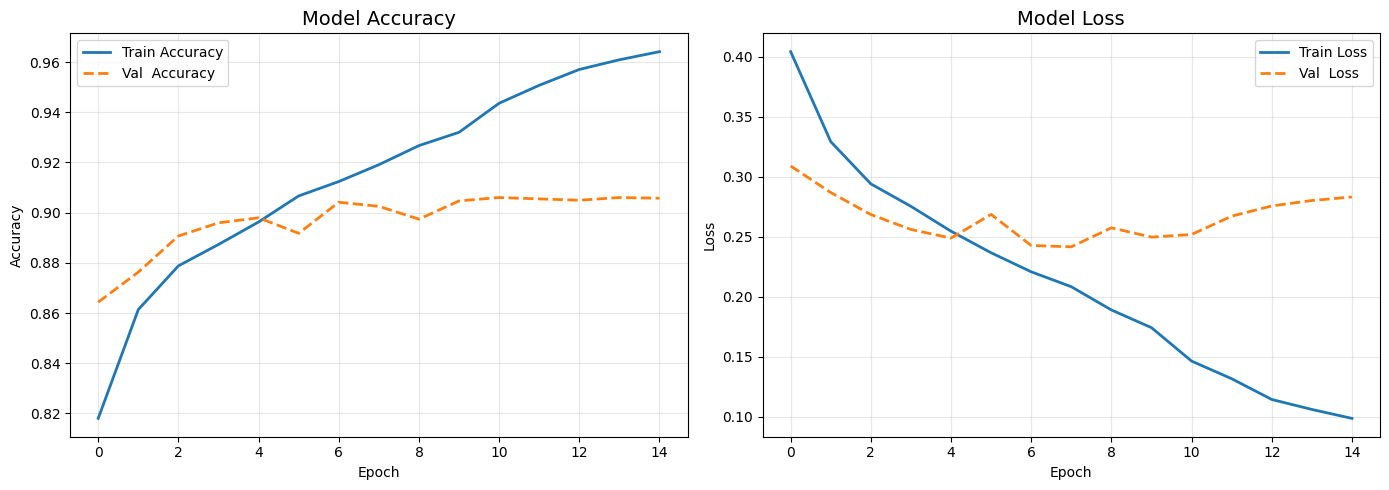

In [ ]:
import matplotlib.pyplot as plt   # Plotting library

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy plot ─────────────────────────────────────────────
axes[0].plot(history.history["accuracy"],     label="Train Accuracy", linewidth=2)
axes[0].plot(history.history["val_accuracy"], label="Val  Accuracy",  linewidth=2, linestyle="--")
axes[0].set_title("Model Accuracy", fontsize=14)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Loss plot ─────────────────────────────────────────────────
axes[1].plot(history.history["loss"],     label="Train Loss", linewidth=2)
axes[1].plot(history.history["val_loss"], label="Val  Loss",  linewidth=2, linestyle="--")
axes[1].set_title("Model Loss", fontsize=14)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("/content/drive/MyDrive/BiLSTM/training_curves.png", dpi=150)   # Save the figure
plt.show()
# print("📊 Training curves saved → training_curves.png")


# Dropout increase

In [ ]:
import re
import string
import pickle
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import contractions
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense, Dropout,
    SpatialDropout1D, GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

# ---- Config ----
CSV_PATH = "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"
NUM_WORDS = 20000
MAXLEN = 300
EMBED_DIM = 300
GLOVE_PICKLE_PATH = "/kaggle/input/datasets/authman/pickled-glove840b300d-for-10sec-loading/glove.840B.300d.pkl"
BATCH_SIZE = 128
EPOCHS = 20
RANDOM_STATE = 42

# ============================================================
# STEP 1 — Load data + preprocess (with negation fix)
# ============================================================
df = pd.read_csv(CSV_PATH)

initial_count = len(df)
df.drop_duplicates(subset=["review"], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Duplicates removed: {initial_count - len(df)} rows dropped, {len(df):,} remaining")

# Keep negation words -- removing them turns "was not good" into "good"
NEGATION_WORDS = {"not", "no", "nor", "never", "none", "neither", "n't"}
STOP_WORDS = set(stopwords.words("english")) - NEGATION_WORDS


def preprocess_text(text: str) -> str:
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = text.replace("\u2013", "-").replace("\u2014", "-")
    text = text.encode("ascii", errors="ignore").decode("ascii")
    text = contractions.fix(text)
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\b\d+\b", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in STOP_WORDS]
    return " ".join(tokens)


print("Preprocessing reviews (negation-safe)...")
df["clean_review"] = df["review"].apply(preprocess_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})
print("Preprocessing complete.")

# ============================================================
# STEP 2 — Split 70 / 15 / 15
# ============================================================
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["label"]
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ============================================================
# STEP 3 — Tokenize (fit on train only)
# ============================================================
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean_review"])


def to_padded_sequences(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")


x_train = to_padded_sequences(train_df["clean_review"])
x_val = to_padded_sequences(val_df["clean_review"])
x_test = to_padded_sequences(test_df["clean_review"])

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

with open("tokenizer_freez.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved tokenizer_freez.pkl")

# ============================================================
# STEP 4 — Embedding matrix (random-init OOV instead of zeros)
# ============================================================
print("Loading GloVe vectors from pickle...")
with open(GLOVE_PICKLE_PATH, "rb") as f:
    glove_vectors = pickle.load(f)
print(f"Loaded {len(glove_vectors)} word vectors")

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)

embedding_matrix = np.random.normal(0, 0.05, (vocab_size, EMBED_DIM))
embedding_matrix[0] = np.zeros(EMBED_DIM)  # padding index stays zero

hits, misses = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    vec = glove_vectors.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        hits += 1
    else:
        misses += 1  # keeps the random vector
print(f"GloVe coverage: {hits} hits, {misses} misses")

# ============================================================
# STEP 5 — Build model (GlobalMaxPooling1D instead of last state)
# ============================================================
model = Sequential([
    Embedding(
        input_dim=vocab_size, output_dim=EMBED_DIM,
        weights=[embedding_matrix], input_length=MAXLEN,
        trainable=False,   # was True — freezing removes 6M trainable params
    ),
    SpatialDropout1D(0.4),
    Bidirectional(LSTM(128, return_sequences=True, recurrent_dropout=0.3)),
    Bidirectional(LSTM(64, return_sequences=True, recurrent_dropout=0.3)),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.6),
    Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# ============================================================
# STEP 6 — Train (with per-epoch train/val acc & loss logged)
# ============================================================
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint("imdb_bilstm_best_freez.h5", monitor="val_accuracy", save_best_only=True, verbose=1),
    CSVLogger("training_log_freez.csv"),  # saves epoch-by-epoch acc/loss/val_acc/val_loss to a CSV
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

# ============================================================
# STEP 7 — Save final model + evaluate on held-out test set
# ============================================================
model.save("imdb_bilstm_final_freez.h5")
print("Saved imdb_bilstm_final_freez.h5")

loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal TEST accuracy: {acc:.4f}")

Duplicates removed: 418 rows dropped, 49,582 remaining
Preprocessing reviews (negation-safe)...
Preprocessing complete.
Train: 34707 | Val: 7437 | Test: 7438
Saved tokenizer_freez.pkl
Loading GloVe vectors from pickle...
Loaded 2196008 word vectors
GloVe coverage: 19503 hits, 496 misses


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 0 (0.00 B)

... (11 outputs left out)


Epoch 13: finished saving model to imdb_bilstm_best_freez.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 633s 2s/step - accuracy: 0.9355 - loss: 0.1703 - val_accuracy: 0.9091 - val_loss: 0.2337 - learning_rate: 5.0000e-04
Epoch 14/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9385 - loss: 0.1629
Epoch 14: val_accuracy did not improve from 0.90910
272/272 ━━━━━━━━━━━━━━━━━━━━ 625s 2s/step - accuracy: 0.9392 - loss: 0.1608 - val_accuracy: 0.9084 - val_loss: 0.2476 - learning_rate: 5.0000e-04
Epoch 15/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9465 - loss: 0.1444
Epoch 15: val_accuracy improved from 0.90910 to 0.90937, saving model to imdb_bilstm_best_freez.h5



Epoch 15: finished saving model to imdb_bilstm_best_freez.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 625s 2s/step - accuracy: 0.9441 - loss: 0.1490 - val_accuracy: 0.9094 - val_loss: 0.2489 - learning_rate: 2.5000e-04
Epoch 16/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9484 - loss: 0.1405
Epoch 16: val_accuracy improved from 0.90937 to 0.90978, saving model to imdb_bilstm_best_freez.h5



Epoch 16: finished saving model to imdb_bilstm_best_freez.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 624s 2s/step - accuracy: 0.9478 - loss: 0.1406 - val_accuracy: 0.9098 - val_loss: 0.2489 - learning_rate: 2.5000e-04
Epoch 17/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9490 - loss: 0.1350
Epoch 17: val_accuracy did not improve from 0.90978
272/272 ━━━━━━━━━━━━━━━━━━━━ 622s 2s/step - accuracy: 0.9485 - loss: 0.1367 - val_accuracy: 0.9071 - val_loss: 0.2535 - learning_rate: 1.2500e-04
Epoch 18/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9514 - loss: 0.1304
Epoch 18: val_accuracy did not improve from 0.90978
272/272 ━━━━━━━━━━━━━━━━━━━━ 620s 2s/step - accuracy: 0.9498 - loss: 0.1323 - val_accuracy: 0.9084 - val_loss: 0.2537 - learning_rate: 1.2500e-04
Epoch 19/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9508 - loss: 0.1334
Epoch 19: val_accuracy did not improve from 0.90978
272/272 ━━━━━━━━━━━━━━━━━━━━ 613s 2s/step - accuracy: 0.9507 - loss: 0.1324 - val_accu

Saved imdb_bilstm_final_freez.h5

Final TEST accuracy: 0.9074


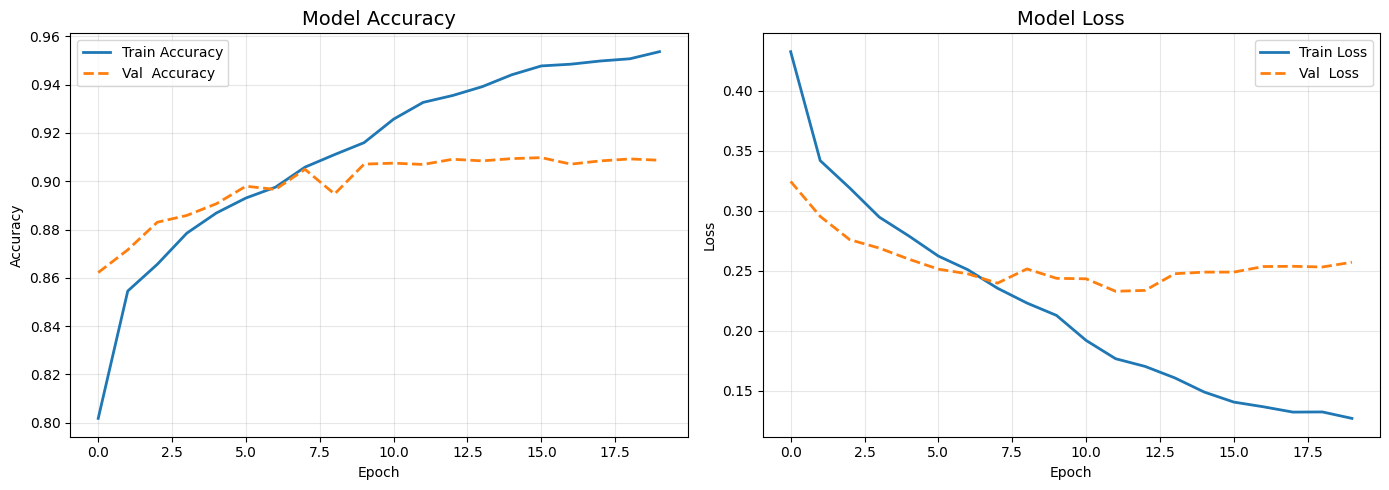

In [ ]:
import matplotlib.pyplot as plt   # Plotting library

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy plot ─────────────────────────────────────────────
axes[0].plot(history.history["accuracy"],     label="Train Accuracy", linewidth=2)
axes[0].plot(history.history["val_accuracy"], label="Val  Accuracy",  linewidth=2, linestyle="--")
axes[0].set_title("Model Accuracy", fontsize=14)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Loss plot ─────────────────────────────────────────────────
axes[1].plot(history.history["loss"],     label="Train Loss", linewidth=2)
axes[1].plot(history.history["val_loss"], label="Val  Loss",  linewidth=2, linestyle="--")
axes[1].set_title("Model Loss", fontsize=14)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("/content/drive/MyDrive/BiLSTM/training_curves.png", dpi=150)   # Save the figure
plt.show()
# print("📊 Training curves saved → training_curves.png")


In [ ]:
!pip install contractions -q

In [ ]:
import re
import string
import pickle
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import contractions
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.regularizers import l2

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense, Dropout,
    SpatialDropout1D, GlobalMaxPooling1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

# ---- Config ----
CSV_PATH = "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"
NUM_WORDS = 20000
MAXLEN = 300
EMBED_DIM = 300
GLOVE_PICKLE_PATH = "/kaggle/input/datasets/authman/pickled-glove840b300d-for-10sec-loading/glove.840B.300d.pkl"
BATCH_SIZE = 128
EPOCHS = 20
RANDOM_STATE = 42

# ============================================================
# STEP 1 — Load data + preprocess (with negation fix)
# ============================================================
df = pd.read_csv(CSV_PATH)

initial_count = len(df)
df.drop_duplicates(subset=["review"], inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"Duplicates removed: {initial_count - len(df)} rows dropped, {len(df):,} remaining")

# Keep negation words -- removing them turns "was not good" into "good"
NEGATION_WORDS = {"not", "no", "nor", "never", "none", "neither", "n't"}
STOP_WORDS = set(stopwords.words("english")) - NEGATION_WORDS


def preprocess_text(text: str) -> str:
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = text.replace("\u2013", "-").replace("\u2014", "-")
    text = text.encode("ascii", errors="ignore").decode("ascii")
    text = contractions.fix(text)
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\b\d+\b", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in STOP_WORDS]
    return " ".join(tokens)


print("Preprocessing reviews (negation-safe)...")
df["clean_review"] = df["review"].apply(preprocess_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})
print("Preprocessing complete.")

# ============================================================
# STEP 2 — Split 70 / 15 / 15
# ============================================================
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["label"]
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ============================================================
# STEP 3 — Tokenize (fit on train only)
# ============================================================
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean_review"])


def to_padded_sequences(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")


x_train = to_padded_sequences(train_df["clean_review"])
x_val = to_padded_sequences(val_df["clean_review"])
x_test = to_padded_sequences(test_df["clean_review"])

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

with open("tokenizer_l2.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved tokenizer_l2.pkl")

# ============================================================
# STEP 4 — Embedding matrix (random-init OOV instead of zeros)
# ============================================================
print("Loading GloVe vectors from pickle...")
with open(GLOVE_PICKLE_PATH, "rb") as f:
    glove_vectors = pickle.load(f)
print(f"Loaded {len(glove_vectors)} word vectors")

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)

embedding_matrix = np.random.normal(0, 0.05, (vocab_size, EMBED_DIM))
embedding_matrix[0] = np.zeros(EMBED_DIM)  # padding index stays zero

hits, misses = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    vec = glove_vectors.get(word)
    if vec is not None:
        embedding_matrix[idx] = vec
        hits += 1
    else:
        misses += 1  # keeps the random vector
print(f"GloVe coverage: {hits} hits, {misses} misses")

# ============================================================
# STEP 5 — Build model (GlobalMaxPooling1D instead of last state)
# ============================================================
model = Sequential([
    Embedding(
        input_dim=vocab_size, output_dim=EMBED_DIM,
        weights=[embedding_matrix], input_length=MAXLEN,
        trainable=True,   # was True — freezing removes 6M trainable params
    ),
    SpatialDropout1D(0.4),
    Bidirectional(LSTM(64, return_sequences=True, recurrent_dropout=0.3)),
    Bidirectional(LSTM(32, return_sequences=True, recurrent_dropout=0.3)),
    GlobalMaxPooling1D(),
    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),     ])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# ============================================================
# STEP 6 — Train (with per-epoch train/val acc & loss logged)
# ============================================================
callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint("imdb_bilstm_best_l2.h5", monitor="val_accuracy", save_best_only=True, verbose=1),
    CSVLogger("training_log_l2.csv"),  # saves epoch-by-epoch acc/loss/val_acc/val_loss to a CSV
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

# ============================================================
# STEP 7 — Save final model + evaluate on held-out test set
# ============================================================
model.save("imdb_bilstm_final_l2.h5")
print("Saved imdb_bilstm_final_l2.h5")

loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal TEST accuracy: {acc:.4f}")

Duplicates removed: 418 rows dropped, 49,582 remaining
Preprocessing reviews (negation-safe)...
Preprocessing complete.
Train: 34707 | Val: 7437 | Test: 7438
Saved tokenizer_l2.pkl
Loading GloVe vectors from pickle...
Loaded 2196008 word vectors
GloVe coverage: 19503 hits, 496 misses


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_4             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_4          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,000,000 (22.89 MB)

 Trainable params: 6,000,000 (22.89 MB)

... (2 outputs left out)


Epoch 1: finished saving model to imdb_bilstm_best_l2.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 633s 2s/step - accuracy: 0.8165 - loss: 0.4395 - val_accuracy: 0.8869 - val_loss: 0.2975 - learning_rate: 0.0010
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8957 - loss: 0.2924
Epoch 2: val_accuracy improved from 0.88692 to 0.90130, saving model to imdb_bilstm_best_l2.h5



Epoch 2: finished saving model to imdb_bilstm_best_l2.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 629s 2s/step - accuracy: 0.8980 - loss: 0.2853 - val_accuracy: 0.9013 - val_loss: 0.2658 - learning_rate: 0.0010
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9237 - loss: 0.2241
Epoch 3: val_accuracy did not improve from 0.90130
272/272 ━━━━━━━━━━━━━━━━━━━━ 640s 2s/step - accuracy: 0.9243 - loss: 0.2216 - val_accuracy: 0.8981 - val_loss: 0.2776 - learning_rate: 0.0010
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9407 - loss: 0.1798
Epoch 4: val_accuracy improved from 0.90130 to 0.90655, saving model to imdb_bilstm_best_l2.h5



Epoch 4: finished saving model to imdb_bilstm_best_l2.h5
272/272 ━━━━━━━━━━━━━━━━━━━━ 633s 2s/step - accuracy: 0.9426 - loss: 0.1760 - val_accuracy: 0.9065 - val_loss: 0.2732 - learning_rate: 0.0010
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9591 - loss: 0.1340
Epoch 5: val_accuracy did not improve from 0.90655
272/272 ━━━━━━━━━━━━━━━━━━━━ 633s 2s/step - accuracy: 0.9594 - loss: 0.1315 - val_accuracy: 0.9045 - val_loss: 0.3099 - learning_rate: 5.0000e-04
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9656 - loss: 0.1124
Epoch 6: val_accuracy did not improve from 0.90655
272/272 ━━━━━━━━━━━━━━━━━━━━ 641s 2s/step - accuracy: 0.9661 - loss: 0.1108 - val_accuracy: 0.9006 - val_loss: 0.3182 - learning_rate: 5.0000e-04
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9743 - loss: 0.0919
Epoch 7: val_accuracy did not improve from 0.90655
272/272 ━━━━━━━━━━━━━━━━━━━━ 645s 2s/step - accuracy: 0.9734 - loss: 0.0914 - val_accuracy: 0.9022 -

Saved imdb_bilstm_final_l2.h5

Final TEST accuracy: 0.9043


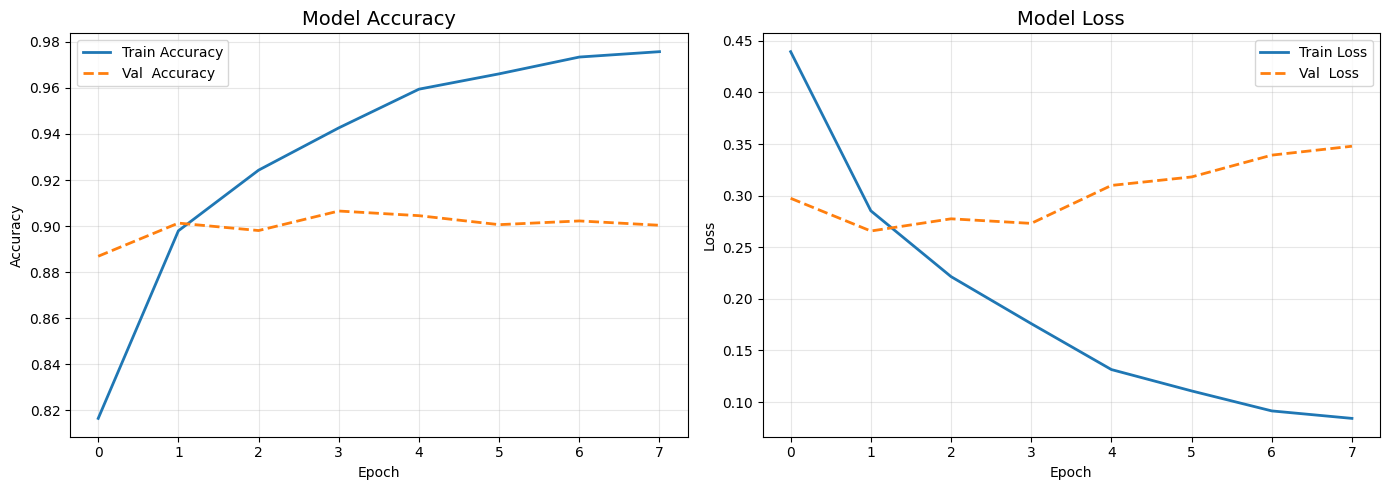

In [ ]:
import matplotlib.pyplot as plt   # Plotting library

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy plot ─────────────────────────────────────────────
axes[0].plot(history.history["accuracy"],     label="Train Accuracy", linewidth=2)
axes[0].plot(history.history["val_accuracy"], label="Val  Accuracy",  linewidth=2, linestyle="--")
axes[0].set_title("Model Accuracy", fontsize=14)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Loss plot ─────────────────────────────────────────────────
axes[1].plot(history.history["loss"],     label="Train Loss", linewidth=2)
axes[1].plot(history.history["val_loss"], label="Val  Loss",  linewidth=2, linestyle="--")
axes[1].set_title("Model Loss", fontsize=14)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig("/content/drive/MyDrive/BiLSTM/training_curves.png", dpi=150)   # Save the figure
plt.show()
# print("📊 Training curves saved → training_curves.png")
